In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [4]:
def inspect_model_pmfs_for_observation(obs, model, atoms):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    return_pmfs = model(observations)
    return_pmfs = return_pmfs[0] # There's only 1 item in batch.
    
    
    ## Display the observation.
    print(f"{observations = }")
    
    # Compute Q-value for each action.
    for a, rpmf in enumerate(return_pmfs):
        q = jnp.sum(rpmf * atoms)
        print(f"Q(a{a}): {q}")
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    # fig = plt.figure()
    # ax = fig.add_subplot(111)
    # x = jnp.arange(action_pmf[0].shape[-1])
    # ax.bar(x, action_pmf[0])
    # ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    # ax.set_xlabel("Action atom")
    # ax.set_ylabel("Probability")
    # ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    n_actions, n_returns = return_pmfs.shape
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()

def inspect_model_pmfs_for_env(env, model, atoms):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    inspect_model_pmfs_for_observation(obs, model, atoms)
    
    return obs

In [5]:
from qnrl.algorithms.c51 import C51
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import Sequential, DistQNetworkLinear

import ale_py
gym.register_envs(ale_py)

# # CartPole.
# env = EnvConfig(env_id="CartPole-v1")
# din = 4
# num_actions = 2
# # z_min = -100
# # z_max = 100
###
# z_min = 0
# z_max = 500

# # FrozenLake-v1
# din = 1
# num_actions = 4
# # env = EnvConfig(env_id="FrozenLake-v1")
# # env = ObservationExpandDims(env=EnvConfig(env_id="FrozenLake-v1"), axis=0)
# env = ObservationExpandDims(env=EnvConfig(env_id="FrozenLake-v1", extra_args=dict(reward_schedule=(2,-1,-0.01))), axis=0)
# # z_min = -100
# # z_max = 100
# z_min = -2
# z_max = 1

# # CliffWalking-v1
# din = 1
# num_actions = 4
# # env = EnvConfig(env_id="CliffWalking-v1")
# env = ObservationExpandDims(env=EnvConfig(env_id="CliffWalking-v1", max_episode_steps=100), axis=0)
# z_min = -100
# z_max = 100

# # MountainCar.
# env = EnvConfig(env_id="MountainCar-v0")
# din = 2
# num_actions = 3
# # z_min = -100
# # z_max = 100
# z_min = -200
# z_max = -1

# Acrobot-v1
din = 6
num_actions = 3
env = EnvConfig(env_id="Acrobot-v1")
# z_min = -100
# z_max = 100
###
z_min = -500
z_max = -1

# # ALE/Asteroids-v5
# din = 128
# num_actions = 14
# env = EnvConfig(env_id="ALE/Asteroids-v5", extra_args=dict(obs_type="ram"))
# z_min = 1
# z_max = 10000

# num_atoms = 101
# num_atoms = 2**7
num_atoms = 2**5

batch_size = 128

# seed = 0
seed = 42

# Experiment configuration.
config = C51(
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=500_000,
    total_timesteps=50_000,
    # total_timesteps=20_000, # quick test default.
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    # env=EnvConfig(env_id="CartPole-v1"),
    # env=EnvConfig(env_id="MountainCar-v0"),
    env=env,
    num_atoms=num_atoms,
    z_min=z_min,
    z_max=z_max,
    model=Sequential(
        layers={
            # 'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
            'QNetworkLinear': DistQNetworkLinear(
                din=din,
                num_actions=num_actions,
                num_atoms=num_atoms,
                douts=[120, 84],
                # douts=[120,],
                # douts=[60,42], # Does well at 20,000 epochs.
                # douts=[30,21], # Does not solve at 20,000 epochs.
                # douts=[30,],
                # douts=[60,],
                rngs_kwargs=dict(default=seed),
            ),
        },
    ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=2.5e-3),
    # optimizer=Adam(learning_rate=1e-3, eps=0.01/batch_size),
    optimizer=Adam(learning_rate=1e-3),
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

New hash
Config String: {"type": "C51", "env": {"env_id": "Acrobot-v1", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "seed": 42, "metric_manager": null, "checkpoint": null, "model": {"type": "Sequential", "layers": {"QNetworkLinear": {"type": "DistQNetworkLinear", "din": 6, "num_actions": 3, "num_atoms": 32, "douts": [120, 84], "rngs_kwargs": {"default": 42}}}, "key_order": ["QNetworkLinear"]}, "optimizer": {"type": "Adam", "learning_rate": 0.001, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "num_atoms": 32, "z_min": -500.0, "z_max": -1.0, "buffer_size": 10000, "batch_size": 128, "total_timesteps": 50000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1, "eps_end": 0.05, "eps_exploration": 0.5}
Config Hash: 56326999-462c-58f6-9025-6917cbd3217e


In [6]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    'QNetworkLinear': {
      'layers': {
        0: {
          'bias': Param( # 120 (480 B)
            value=Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                   0.], dtype=float32)
          ),
          'kernel': Param( # 720 (2.9 KB)
            value=Array([[ 3.36319916e-02, -2.14662984e-01,  5.52968621e-01,
                     2.29223102e-01,  1.32897913e-01,  1.37284473e-01,
                     2.5391

In [7]:
jnp.asarray(np.linspace(start=z_min, stop=z_max, num=num_atoms))

Array([-500.        , -483.90322581, -467.80645161, -451.70967742,
       -435.61290323, -419.51612903, -403.41935484, -387.32258065,
       -371.22580645, -355.12903226, -339.03225806, -322.93548387,
       -306.83870968, -290.74193548, -274.64516129, -258.5483871 ,
       -242.4516129 , -226.35483871, -210.25806452, -194.16129032,
       -178.06451613, -161.96774194, -145.87096774, -129.77419355,
       -113.67741935,  -97.58064516,  -81.48387097,  -65.38709677,
        -49.29032258,  -33.19354839,  -17.09677419,   -1.        ],      dtype=float64)

In [8]:
qnrl.tools.get_model_total_parameter_count(config.model)

19164

observations = Array([[ 0.9997523 ,  0.02225597,  0.99652755,  0.08326352, -0.01638004,
        -0.09091111]], dtype=float32)
Q(a0): -241.5908928283401
Q(a1): -256.6136656976755
Q(a2): -255.37445726786413


<Figure size 640x480 with 0 Axes>

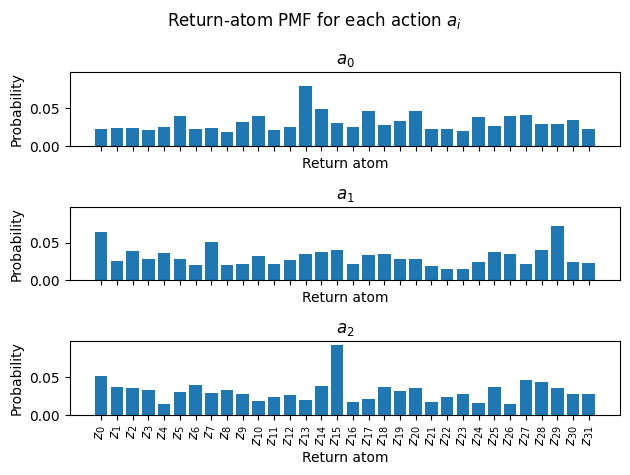

In [9]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)
obs_inspect = inspect_model_pmfs_for_env(config.env.make(), config.model, atoms)

In [10]:
train = True
save_metrics = True
metric_filepath = Path(f"./metrics/{cfg_hash}.json")

In [11]:
if metric_filepath.exists() and not train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train()
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 56326999-462c-58f6-9025-6917cbd3217e
History: metrics/56326999-462c-58f6-9025-6917cbd3217e.json


 20%|█▉        | 9946/50000 [00:09<00:39, 1010.54step/s, episode_step=9833, episode_reward=-365, episode_length=366, episode_time=0.358]/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 50000/50000 [01:12<00:00, 687.35step/s, episode_step=5e+4, episode_reward=-124, episode_length=125, episode_time=0.191, loss_step=5e+4, loss=1.8105459, metric_step=5e+4, cross_entropy=1.8116757, kl_div=0.020900605]      


Text(0, 0.5, 'episode_reward')

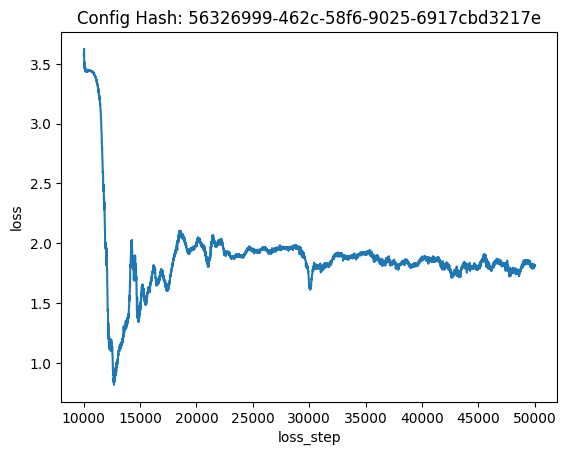

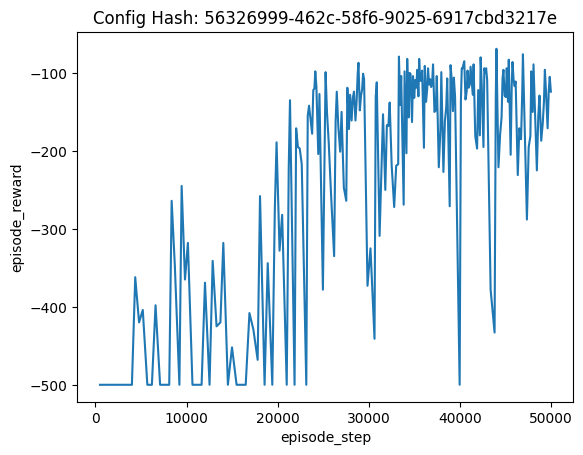

In [12]:
import matplotlib.pyplot as plt

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

./figures/56326999-462c-58f6-9025-6917cbd3217e.pdf


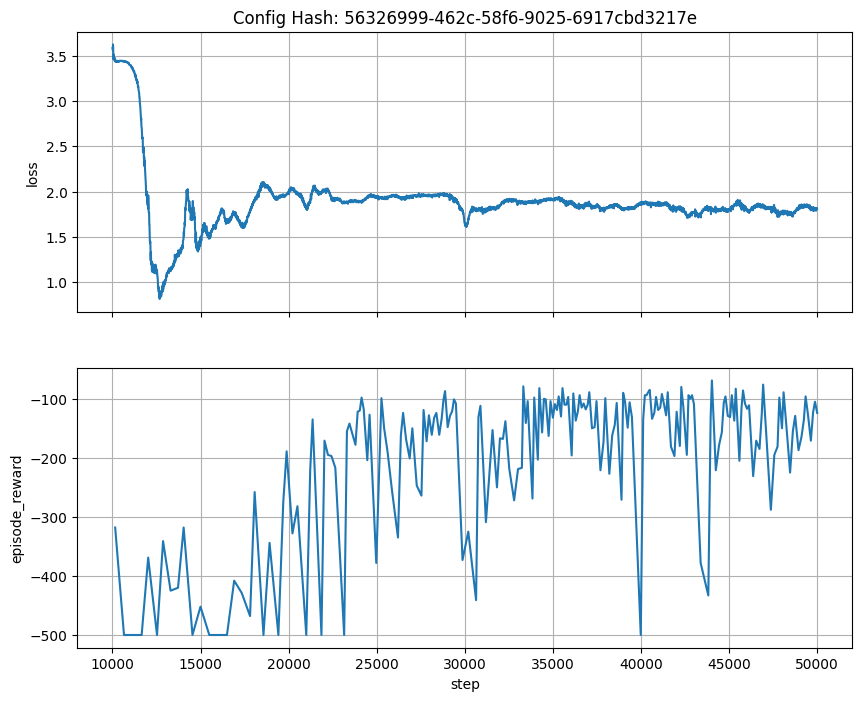

In [13]:
# Plot loss and episode reward on the same plot.

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
axs = axs.squeeze()

axs[0].set_title(f"Config Hash: {cfg_hash}")
plt.xlabel('step')

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['loss_step']) >= config.learning_starts
history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
history_dict['loss'] = np.array(history_dict['loss'])[idx]

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['episode_step']) >= config.learning_starts
history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

axs[0].plot(history_dict['loss_step'], history_dict['loss'])
axs[0].set_ylabel('loss')
axs[0].grid() # Turn on a grid.

axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
axs[1].set_ylabel('episode_reward')
axs[1].grid() # Turn on a grid.

# Save the figure file.
figfile = f"./figures/{cfg_hash}.pdf"
fig.savefig(figfile)
print(figfile)

In [14]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('episode_step','episode_reward','episode_length','episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 112/50000 [00:00<00:11, 4243.02step/s, episode_step=112, episode_reward=-112, episode_length=113, episode_time=0.0265]

episode_step: 112
episode_reward: -112.0
episode_length: 113
episode_time: 0.026511


observations = Array([[ 0.9997523 ,  0.02225597,  0.99652755,  0.08326352, -0.01638004,
        -0.09091111]], dtype=float32)
Q(a0): -57.192629735931476
Q(a1): -57.20322187543631
Q(a2): -57.12123815785307


<Figure size 640x480 with 0 Axes>

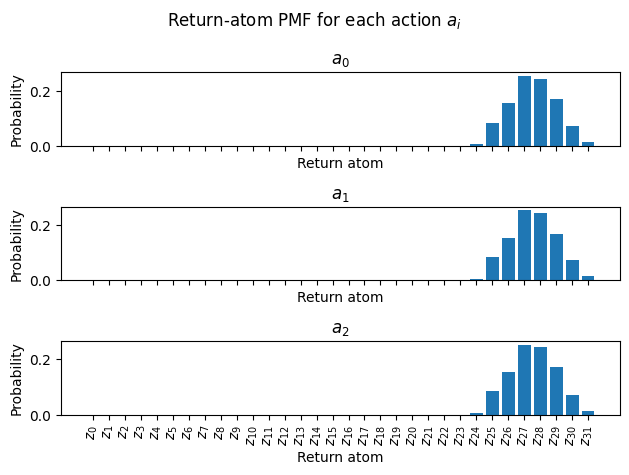

In [15]:
# Inspect the model again using the same observation used prior to training.
inspect_model_pmfs_for_observation(obs_inspect, config.model, atoms)

In [16]:
# obs_tmp=jnp.array([ 0.01716913, -0.02654778, -0.04510068, -0.00686742])
# inspect_model_pmfs_for_observation(obs_tmp, config.model, atoms)

In [17]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model, atoms)

In [18]:
# Evaluate multiple times and preserve results.
# n_runs = 10
# n_runs = 50
n_runs = 100
# n_runs = 1000
eval_metric_dict_runs = []
key = jax.random.PRNGKey(seed=config.seed)
for r in range(n_runs):
    
    # Generate a new random key.
    key, subkey = jax.random.split(key=key)
    
    eval_metric_list = config.eval(seed=int(subkey[0]))
    eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    eval_metric_dict['seed'] = int(subkey[0])
    eval_metric_dict_runs.append(eval_metric_dict)

# Report statistics across all runs.
for key in ('episode_step','episode_reward','episode_length','episode_time',):
    l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {jnp.min(l)}")
    print(f"{key}: max: {jnp.max(l)}")
    print(f"{key}: mean: {jnp.mean(l)}")
    print(f"{key}: std: {jnp.std(l)}")

  0%|          | 72/50000 [00:00<00:09, 5203.13step/s, episode_step=72, episode_reward=-72, episode_length=73, episode_time=0.0139]


episode_step: min: 72
episode_step: max: 235
episode_step: mean: 105.23
episode_step: std: 26.319899315916842
episode_reward: min: -235.0
episode_reward: max: -72.0
episode_reward: mean: -105.23
episode_reward: std: 26.319899315916842
episode_length: min: 73
episode_length: max: 236
episode_length: mean: 106.23
episode_length: std: 26.319899315916842
episode_time: min: 0.013827
episode_time: max: 0.043586
episode_time: mean: 0.022741640000000004
episode_time: std: 0.005808222754888107


## Record a run as a video

tmpdir = '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp4zscyauw'


/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp4zscyauw folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
  0%|          | 104/50000 [00:00<00:48, 1035.77step/s, episode_step=104, episode_reward=-104, episode_length=105, episode_time=0.671]


episode_step: min: 104
episode_step: max: 104
episode_step: mean: 104.0
episode_step: std: 0.0
episode_reward: min: -104.0
episode_reward: max: -104.0
episode_reward: mean: -104.0
episode_reward: std: 0.0
episode_length: min: 105
episode_length: max: 105
episode_length: mean: 105.0
episode_length: std: 0.0
episode_time: min: 0.671078
episode_time: max: 0.671078
episode_time: mean: 0.671078
episode_time: std: 0.0
os.listdir(tmpdir) = ['rl-video-episode-0.mp4']
MoviePy - Building file /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp4zscyauw/rl-video-episode-0.gif with imageio.


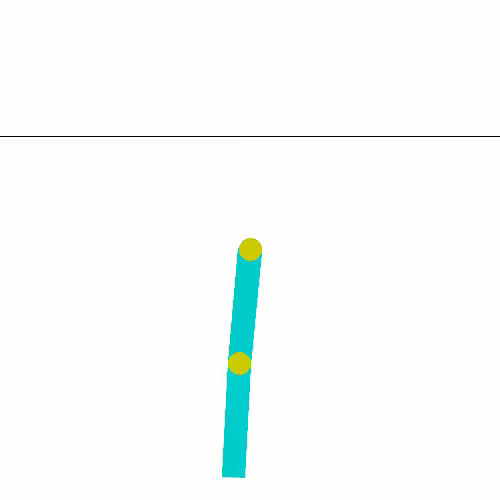

In [19]:
import os
import tempfile
from IPython.display import display, Video, Image
from moviepy import VideoFileClip

with tempfile.TemporaryDirectory() as tmpdir:
    print(f"{tmpdir = }")

    # Create wrapper for recording video.
    env_wrappers = [
        lambda env: gym.wrappers.RecordVideo(env, video_folder=tmpdir, episode_trigger=lambda x: True, disable_logger=True),
    ]
    
    # Evaluate multiple times and preserve results.
    n_runs = 1
    eval_metric_dict_runs = []
    key = jax.random.PRNGKey(seed=1423)
    for r in range(n_runs):
        
        # Generate a new random key.
        key, subkey = jax.random.split(key=key)
        
        # Evaluate the model within environment seeded from random subkey.
        eval_metric_list = config.eval(seed=int(subkey[0]), env=config.env.make(render_mode='rgb_array'), model_policy=config.model, total_timesteps=config.total_timesteps, env_wrappers=env_wrappers)
        eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
        eval_metric_dict['seed'] = int(subkey[0])
        eval_metric_dict_runs.append(eval_metric_dict)

    # Report statistics across all runs.
    for key in ('episode_step','episode_reward','episode_length','episode_time',):
        l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
        print(f"{key}: min: {jnp.min(l)}")
        print(f"{key}: max: {jnp.max(l)}")
        print(f"{key}: mean: {jnp.mean(l)}")
        print(f"{key}: std: {jnp.std(l)}")
    
    print(f"{os.listdir(tmpdir) = }")
    
    videofilepath = Path(tmpdir)/os.listdir(tmpdir)[0]
    
    # Build a GIF from the video file.
    giffilepath = Path(tmpdir)/(videofilepath.stem + '.gif')
    clip = VideoFileClip(videofilepath)
    clip.write_gif(giffilepath, fps=15)
    
    # display(Video(videofilepath, embed=True, html_attributes="controls muted loop autoplay"))
    display(Image(filename=giffilepath))